<a href="https://colab.research.google.com/github/bharatsharma2222/stats_practicals/blob/main/Practical11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import gamma

# Official SILSO monthly sunspot dataset
url = "https://www.sidc.be/SILSO/DATA/SN_m_tot_V2.0.csv"

columns = [
    "year", "month", "date", "sunspots",
    "deviation", "observations", "definitive"
]

df = pd.read_csv(url, sep=";", header=None, names=columns)

# Keep assignment data: January 1749 to November 2018
df = df[
    ((df["year"] > 1749) |
     ((df["year"] == 1749) & (df["month"] >= 1))) &
    ((df["year"] < 2018) |
     ((df["year"] == 2018) & (df["month"] <= 11)))
].copy()

# Remove missing values (-1)
df = df[df["sunspots"] >= 0].copy()

print(df.head())
print("Dataset shape:", df.shape)
print(df.describe())


   year  month      date  sunspots  deviation  observations  definitive
0  1749      1  1749.042      96.7       -1.0            -1           1
1  1749      2  1749.123     104.3       -1.0            -1           1
2  1749      3  1749.204     116.7       -1.0            -1           1
3  1749      4  1749.288      92.8       -1.0            -1           1
4  1749      5  1749.371     141.7       -1.0            -1           1
Dataset shape: (3239, 7)
              year        month         date     sunspots    deviation  \
count  3239.000000  3239.000000  3239.000000  3239.000000  3239.000000   
mean   1883.458475     6.498302  1883.956337    82.385829     5.580642   
std      77.929971     3.451765    77.930251    67.817453     5.225088   
min    1749.000000     1.000000  1749.042000     0.000000    -1.000000   
25%    1816.000000     3.500000  1816.498000    24.550000    -1.000000   
50%    1883.000000     6.000000  1883.958000    68.300000     5.300000   
75%    1951.000000     9.

##**Step 1: Plot the data over the years
We use a line graph to understand how sunspot numbers change over time.**

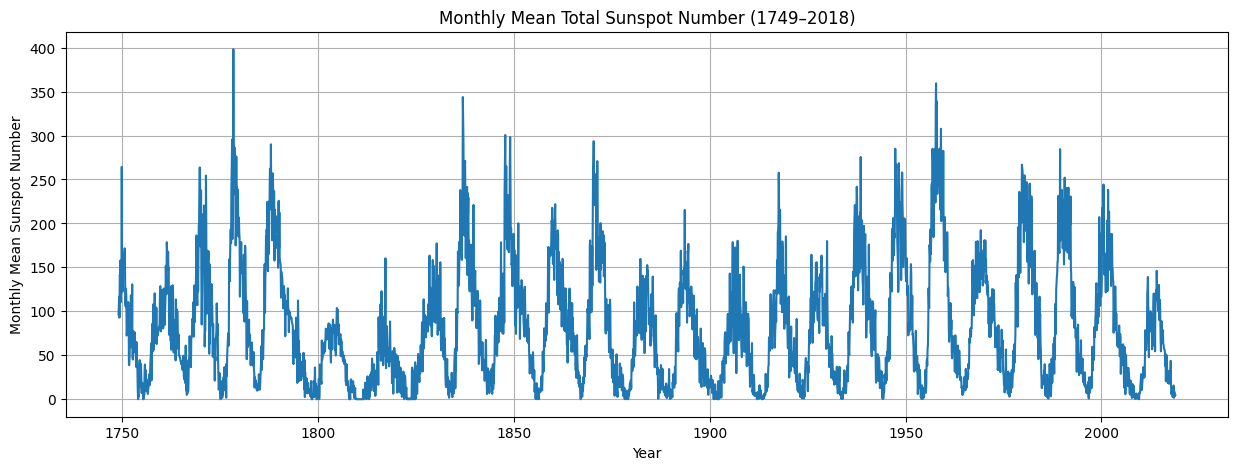

In [ ]:

plt.figure(figsize=(15, 5))

plt.plot(df["date"], df["sunspots"])

plt.title("Monthly Mean Total Sunspot Number (1749–2018)")
plt.xlabel("Year")
plt.ylabel("Monthly Mean Sunspot Number")
plt.grid(True)

plt.show()


**Conclusion: The graph shows that sunspot activity increases and decreases over time. These repeated increases and decreases represent the solar cycle.**

##**Step 2: Model the phenomenon using a Gamma distribution. The assignment assumes a new cycle resets every 12 years. Since the data is monthly, 12 years equals 144 months.We create a cycle number for each observation and plot the data with cycle boundaries.**

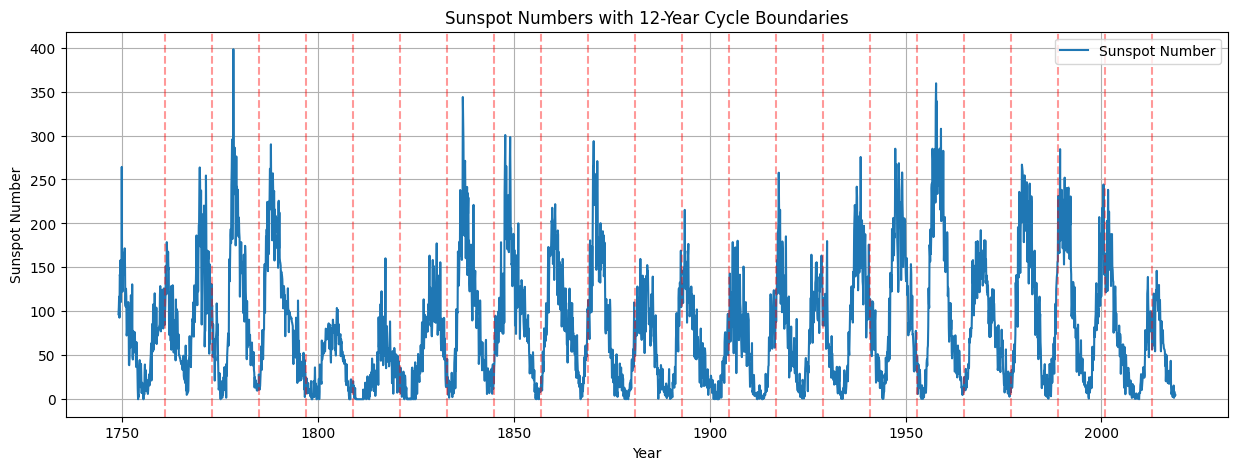

    year  month  sunspots  cycle
0   1749      1      96.7      1
1   1749      2     104.3      1
2   1749      3     116.7      1
3   1749      4      92.8      1
4   1749      5     141.7      1
5   1749      6     139.2      1
6   1749      7     158.0      1
7   1749      8     110.5      1
8   1749      9     126.5      1
9   1749     10     125.8      1
10  1749     11     264.3      1
11  1749     12     142.0      1
12  1750      1     122.2      1
13  1750      2     126.5      1
14  1750      3     148.7      1


In [ ]:

# One cycle = 12 years = 144 months
df["cycle"] = (
    ((df["year"] - 1749) * 12 + df["month"] - 1) // 144
) + 1

plt.figure(figsize=(15, 5))

plt.plot(df["date"], df["sunspots"], label="Sunspot Number")

# Mark every 12-year cycle boundary
for year in range(1761, 2019, 12):
    plt.axvline(year, color="red", linestyle="--", alpha=0.4)

plt.title("Sunspot Numbers with 12-Year Cycle Boundaries")
plt.xlabel("Year")
plt.ylabel("Sunspot Number")
plt.legend()
plt.grid(True)

plt.show()

print(df[["year", "month", "sunspots", "cycle"]].head(15))


Gamma Shape (a): 1.1742848202497331
Gamma Scale (b): 71.64020804539345


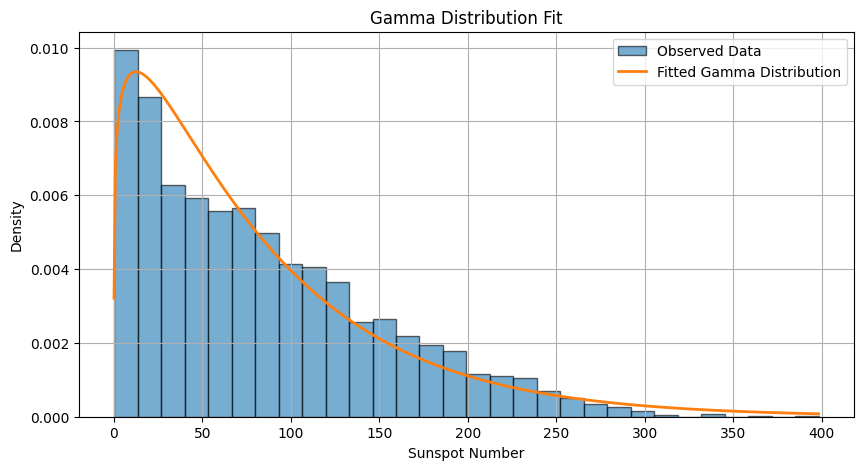

In [ ]:

# Gamma distribution requires positive observations
sunspots = df.loc[df["sunspots"] > 0, "sunspots"].values

# Fit Gamma distribution using maximum likelihood
a_fit, loc_fit, b_fit = gamma.fit(sunspots, floc=0)

print("Gamma Shape (a):", a_fit)
print("Gamma Scale (b):", b_fit)

x = np.linspace(0.01, sunspots.max(), 500)

plt.figure(figsize=(10, 5))

plt.hist(sunspots, bins=30, density=True,
         alpha=0.6, edgecolor="black", label="Observed Data")

plt.plot(
    x,
    gamma.pdf(x, a=a_fit, scale=b_fit),
    linewidth=2,
    label="Fitted Gamma Distribution"
)

plt.title("Gamma Distribution Fit")
plt.xlabel("Sunspot Number")
plt.ylabel("Density")
plt.legend()
plt.grid(True)

plt.show()


**Conclusion: The Gamma distribution provides a probability model for positive sunspot counts. It is useful for modelling positive, right-skewed data.**

##**Step 3: Histogram of sunspot counts**

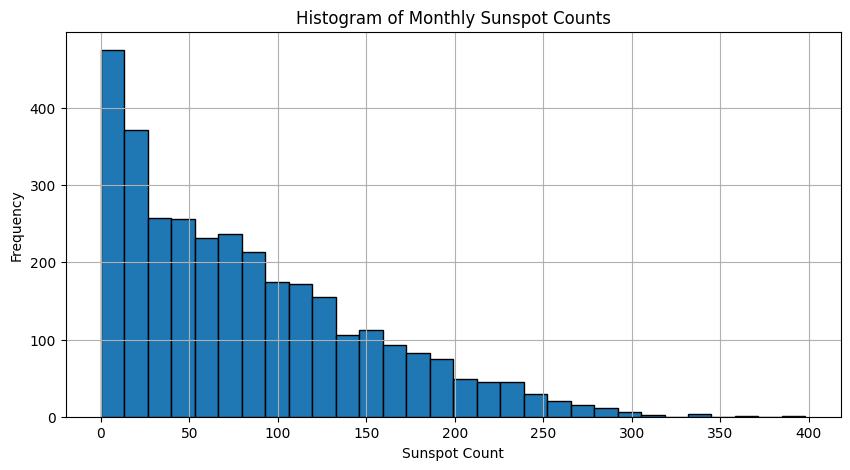

In [ ]:

plt.figure(figsize=(10, 5))

plt.hist(df["sunspots"], bins=30, edgecolor="black")

plt.title("Histogram of Monthly Sunspot Counts")
plt.xlabel("Sunspot Count")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()


**Conclusion: The histogram shows the frequency distribution of monthly sunspot counts. Most observations occur at lower or moderate values, while some months have much higher sunspot activity.**

##**Step 4: MCMC for a = 4 and b = 10Here we use the initial values:**

In [ ]:

# Log posterior function
def log_posterior(log_a, log_b, data):

    a = np.exp(log_a)
    b = np.exp(log_b)

    # Gamma log likelihood
    likelihood = np.sum(
        gamma.logpdf(data, a=a, loc=0, scale=b)
    )

    # Weak prior on log parameters, centered at a=4 and b=10
    prior = (
        -0.5 * ((log_a - np.log(4)) / 2) ** 2
        -0.5 * ((log_b - np.log(10)) / 2) ** 2
    )

    return likelihood + prior


# Metropolis-Hastings MCMC
np.random.seed(42)

n_samples = 30000

a_current = 4
b_current = 10

log_a_current = np.log(a_current)
log_b_current = np.log(b_current)

chain_a = []
chain_b = []

accepted = 0

for i in range(n_samples):

    # Propose new values
    proposed_log_a = np.random.normal(log_a_current, 0.12)
    proposed_log_b = np.random.normal(log_b_current, 0.12)

    current_prob = log_posterior(
        log_a_current, log_b_current, sunspots
    )

    proposed_prob = log_posterior(
        proposed_log_a, proposed_log_b, sunspots
    )

    # Acceptance probability
    acceptance = np.exp(min(0, proposed_prob - current_prob))

    if np.random.rand() < acceptance:
        log_a_current = proposed_log_a
        log_b_current = proposed_log_b
        accepted += 1

    chain_a.append(np.exp(log_a_current))
    chain_b.append(np.exp(log_b_current))


chain_a = np.array(chain_a)
chain_b = np.array(chain_b)

print("Acceptance Rate:", accepted / n_samples)
print("Total MCMC Samples:", n_samples)


Acceptance Rate: 0.046966666666666664
Total MCMC Samples: 30000


**Conclusion: The three groups help us compare how the Gamma distribution changes across MCMC samples. The first 50 samples may differ from later samples, while the last 50 samples should be closer to the distribution represented by the converged chain.**

##**Step 5: Visualise traces of a and b and their histograms**

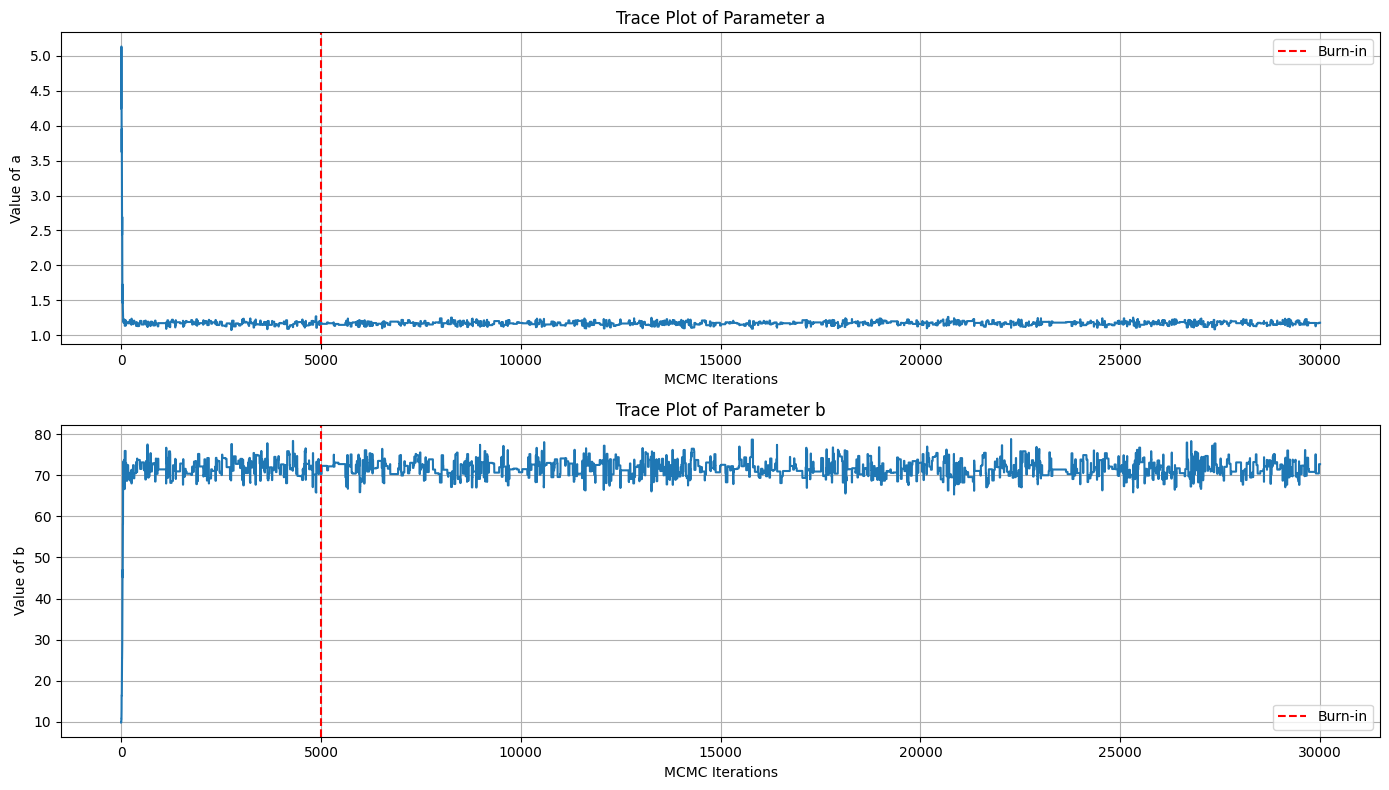

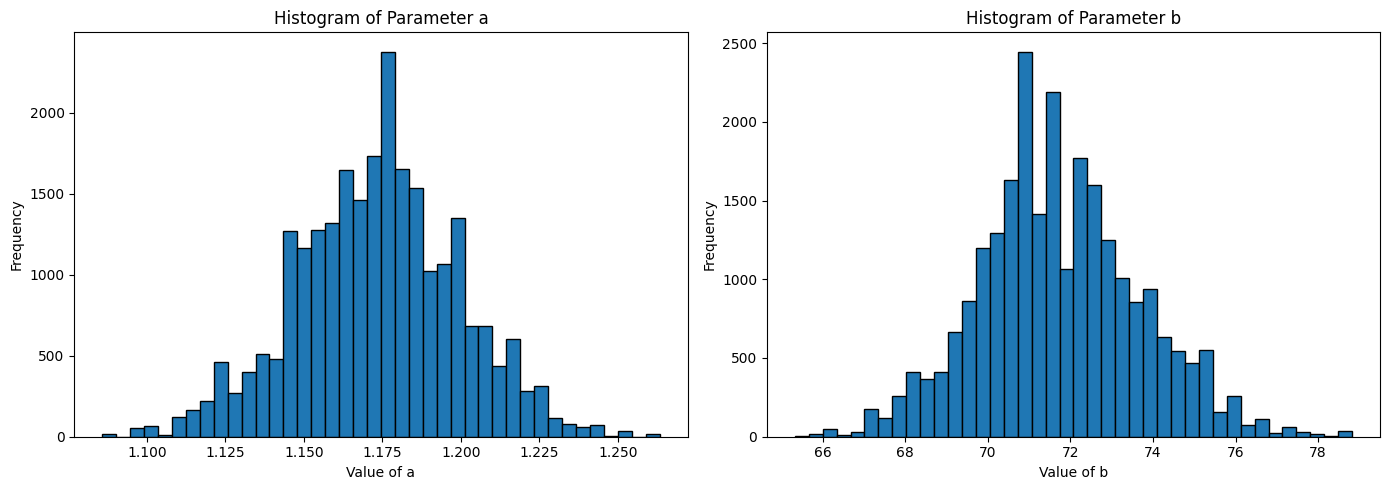

In [ ]:

# Define burn-in
burn_in = 5000

# Remove initial 5000 samples
posterior_a = chain_a[burn_in:]
posterior_b = chain_b[burn_in:]

# Trace plots
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(chain_a)
axes[0].axvline(burn_in, color="red", linestyle="--",
                label="Burn-in")
axes[0].set_title("Trace Plot of Parameter a")
axes[0].set_xlabel("MCMC Iterations")
axes[0].set_ylabel("Value of a")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(chain_b)
axes[1].axvline(burn_in, color="red", linestyle="--",
                label="Burn-in")
axes[1].set_title("Trace Plot of Parameter b")
axes[1].set_xlabel("MCMC Iterations")
axes[1].set_ylabel("Value of b")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Histograms after burn-in
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(posterior_a, bins=40, edgecolor="black")
axes[0].set_title("Histogram of Parameter a")
axes[0].set_xlabel("Value of a")
axes[0].set_ylabel("Frequency")

axes[1].hist(posterior_b, bins=40, edgecolor="black")
axes[1].set_title("Histogram of Parameter b")
axes[1].set_xlabel("Value of b")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


**Conclusion: Trace plots show how parameter values change during MCMC iterations. Histograms show the posterior distributions of a and b. Removing burn-in samples helps reduce the influence of the initial parameter values.**

##**Step 6: Prediction of a and b**

Prediction / Estimation of Parameters
--------------------------------------
Estimated a: 1.1733452903727466
95% Credible Interval for a: [1.12092622 1.22377143]

Estimated b: 71.71667706932345
95% Credible Interval for b: [67.93079879 75.6814218 ]

Simulated Sunspot Counts for 12 Months:
[ 99.14509732  51.60411193  46.12547426  46.12637743 235.07667649
 126.07548863  34.35341953 103.40525801  77.58764206   1.69502528
  15.1814579   83.34895028]


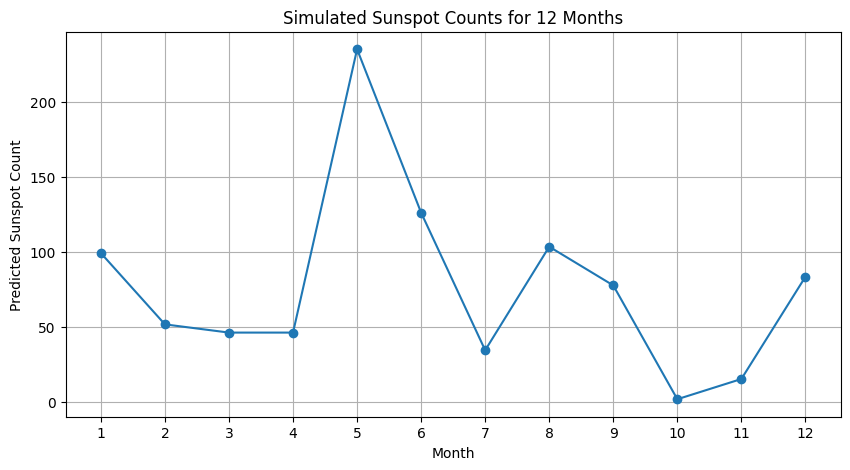

In [ ]:

# Posterior parameter estimates
a_mean = np.mean(posterior_a)
b_mean = np.mean(posterior_b)

a_interval = np.percentile(posterior_a, [2.5, 97.5])
b_interval = np.percentile(posterior_b, [2.5, 97.5])

print("Prediction / Estimation of Parameters")
print("--------------------------------------")

print("Estimated a:", a_mean)
print("95% Credible Interval for a:", a_interval)

print("\nEstimated b:", b_mean)
print("95% Credible Interval for b:", b_interval)


# Simulate 12 future monthly values under the fitted Gamma model
np.random.seed(42)

predicted_sunspots = gamma.rvs(
    a=a_mean,
    scale=b_mean,
    size=12
)

print("\nSimulated Sunspot Counts for 12 Months:")
print(predicted_sunspots)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 13),
    predicted_sunspots,
    marker="o"
)

plt.title("Simulated Sunspot Counts for 12 Months")
plt.xlabel("Month")
plt.ylabel("Predicted Sunspot Count")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()


**Conclusion: The posterior mean values provide estimates of the Gamma parameters a and b. The simulated values show possible monthly sunspot counts under the fitted Gamma model. This is a simple probabilistic simulation, not a full time-series forecast.**